Dataset loaded successfully!
Dataset dimensions: (21025, 202)
Number of spectral bands: 200
Number of pixels: 21025

PCA Results
Reduced dimensions: (21025, 30)
Explained variance: 98.44 %

K-Means clustering completed!

Cluster Distribution:
Cluster 1: 1595 pixels
Cluster 2: 1581 pixels
Cluster 3: 2024 pixels
Cluster 4: 350 pixels
Cluster 5: 758 pixels
Cluster 6: 2738 pixels
Cluster 7: 152 pixels
Cluster 8: 938 pixels
Cluster 9: 1220 pixels
Cluster 10: 774 pixels
Cluster 11: 1249 pixels
Cluster 12: 540 pixels
Cluster 13: 2308 pixels
Cluster 14: 2203 pixels
Cluster 15: 1386 pixels
Cluster 16: 1209 pixels


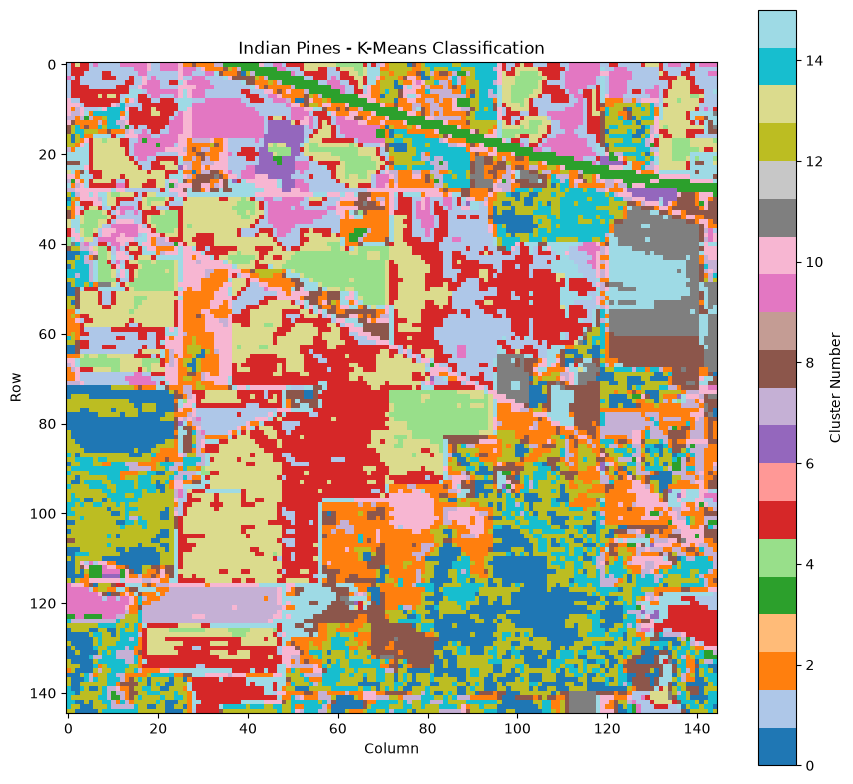

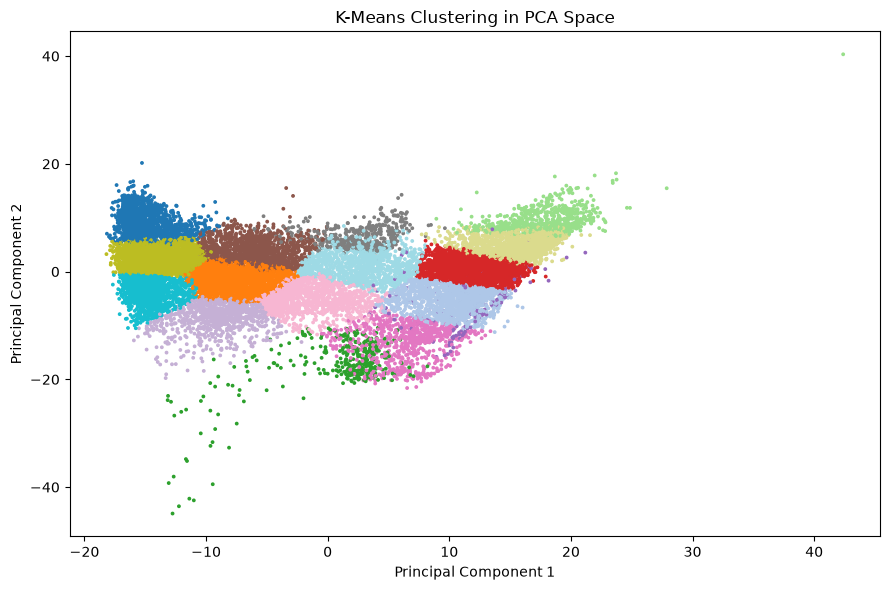

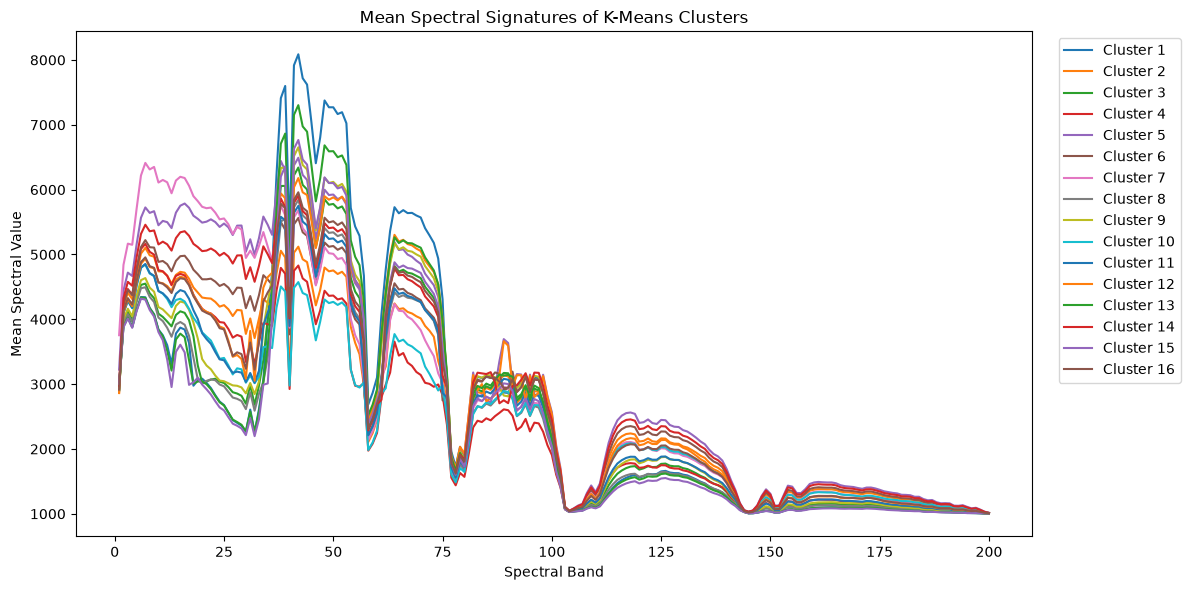


Results saved successfully!
CSV: indian_pines_kmeans_results.csv
Map: indian_pines_classification_map.npy


In [3]:

# K-MEANS CLUSTERING FOR INDIAN PINES HYPERSPECTRAL DATA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Load the dataset
data = pd.read_csv("indian_pines (1).csv")

print("Dataset loaded successfully!")
print("Dataset dimensions:", data.shape)

# 2. Extract spectral bands
band_columns = [c for c in data.columns if c.startswith("band_")]
band_columns = sorted(band_columns, key=lambda c: int(c.split("_")[1]))

X = data[band_columns].values

print("Number of spectral bands:", len(band_columns))
print("Number of pixels:", X.shape[0])

# 3. Handle missing values
X = np.nan_to_num(X, nan=0.0)

# 4. Standardize the spectral data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Apply PCA for dimensionality reduction
pca = PCA(n_components=30)
X_pca = pca.fit_transform(X_scaled)

print("\nPCA Results")
print("Reduced dimensions:", X_pca.shape)
print("Explained variance:",
      round(np.sum(pca.explained_variance_ratio_) * 100, 2), "%")

# 6. Apply K-Means clustering
kmeans = KMeans(
    n_clusters=16,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca)

print("\nK-Means clustering completed!")

# 7. Display cluster distribution
unique, counts = np.unique(clusters, return_counts=True)

print("\nCluster Distribution:")
for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster + 1}: {count} pixels")

# 8. Reconstruct the spatial classification map
rows = data["row"].astype(int).to_numpy()
cols = data["col"].astype(int).to_numpy()

# Automatically handle zero-based or one-based coordinates
if rows.min() == 1 and cols.min() == 1:
    rows = rows - 1
    cols = cols - 1

height = rows.max() + 1
width = cols.max() + 1

classification_map = np.full((height, width), -1)

classification_map[rows, cols] = clusters

# 9. Visualize the classification map
plt.figure(figsize=(9, 8))
plt.imshow(classification_map, cmap="tab20")
plt.colorbar(label="Cluster Number")
plt.title("Indian Pines - K-Means Classification")
plt.xlabel("Column")
plt.ylabel("Row")
plt.tight_layout()
plt.show()

# 10. Visualize PCA clustering
plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="tab20",
    s=3
)
plt.title("K-Means Clustering in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

# 11. Plot mean spectral signatures of clusters
plt.figure(figsize=(12, 6))

for cluster in unique:
    mean_spectrum = X[clusters == cluster].mean(axis=0)
    plt.plot(
        range(1, len(band_columns) + 1),
        mean_spectrum,
        label=f"Cluster {cluster + 1}"
    )

plt.xlabel("Spectral Band")
plt.ylabel("Mean Spectral Value")
plt.title("Mean Spectral Signatures of K-Means Clusters")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 12. Save classification results
data["Cluster"] = clusters + 1

data.to_csv("indian_pines_kmeans_results.csv", index=False)

np.save("indian_pines_classification_map.npy",
        classification_map)

print("\nResults saved successfully!")
print("CSV: indian_pines_kmeans_results.csv")
print("Map: indian_pines_classification_map.npy")
